In [ ]:
#Imports
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
# Load data
file_path = 'data/transactions.zip'
data = pd.read_csv(file_path)

# Explore the data
print(data.head())
print(data.info())


         V1        V2        V3        V4        V5        V6        V7  \
0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  Amount  Class  
0  0.098698  0.363787  149.62      0  
1  0.085102 -0.255425    2.69      0  
2  0.247676 -1.514654  378.66      0  
3  0.377436 -1.387024  123.50      0  
4 -0.270533  0.817739   69.99      0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 11 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   V1      284807 non-null  float64
 1   V2      284807 non-null  float64
 2   V3      284807 non-null  float64
 3   V4      2

In [ ]:
# Define features and target
X = data.drop('Class', axis=1)
y = data['Class']

In [ ]:
# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
# Handle class imbalance using SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

In [27]:
# Define the model
model = Sequential()
model.add(Dense(64, input_dim=X_train_resampled.shape[1], activation='relu'))
model.add(Dropout(0.5))  # Dropout for regularization
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='sigmoid'))  # Output layer for binary classification


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# # Model set-up
# number_input_features = 10
# hidden_nodes_layer1 = 15
# hidden_nodes_layer2 = 5

In [ ]:

# # Define the LSTM RNN model
# model = Sequential()

# # Layer 1
# model.add(
#     Dense(units=hidden_nodes_layer1, input_dim=number_input_features, activation="relu")
# )

# # Layer 2
# model.add(Dense(units=hidden_nodes_layer2, activation="relu"))

# # Output layer
# model.add(Dense(1, activation="sigmoid"))

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [28]:
# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [29]:
# Train the model
history = model.fit(X_train_resampled, y_train_resampled, epochs=1000, batch_size=1000, verbose = 1)

Epoch 1/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8558 - loss: 0.3162
Epoch 2/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9427 - loss: 0.1478
Epoch 3/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9526 - loss: 0.1248
Epoch 4/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9578 - loss: 0.1114
Epoch 5/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9624 - loss: 0.0986
Epoch 6/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9647 - loss: 0.0902
Epoch 7/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9675 - loss: 0.0834
Epoch 8/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9702 - loss: 0.0766
Epoch 9/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9721 - loss: 0.0736
Epoch 10/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9735 - loss: 0.0692
Epoch 11/1000
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9745 - loss: 0.0667
Epoch 12/1000
399/399 ━━━━━━━━

In [30]:
# Predict on the test set
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)  # Convert probabilities to binary predictions

2671/2671 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step


In [31]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85307
           1       0.36      0.82      0.50       136

    accuracy                           1.00     85443
   macro avg       0.68      0.91      0.75     85443
weighted avg       1.00      1.00      1.00     85443



In [32]:
#Confusion Matrix For RNN
tn_rnn , fp_rnn , fn_rnn , tp_rnn = confusion_matrix(y_test , y_pred).ravel()

#Dataframe ro display confusion matrix from The RNN LSTM Model

cm_rnn_df = pd.DataFrame(
    {
        "Positive(1)":[f"TP={tp_rnn}" , f"FP={fp_rnn}"],
        "Negative(0)":[f"FN={fn_rnn}" , f"TN={tn_rnn}"],
    },
    index=["Positive(1)" , "Negative(0)"],
)
cm_rnn_df.index.name = "Actual"
cm_rnn_df.columns.name = "Predicted"
print("Confusion Matrix From the RNN LSTM Model")
display(cm_rnn_df)

Confusion Matrix From the RNN LSTM Model


Predicted,Positive(1),Negative(0)
Actual,,
Positive(1),TP=112,FN=24
Negative(0),FP=197,TN=85110


In [33]:
#Plotting the ROC Curve
from sklearn.metrics import roc_curve , auc

In [34]:
test_predictions_rnn = model.predict(X_test , batch_size=1000)

86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [35]:
#Data For ROC Curve - RNN LSTM Model
fpr_test_rnn , tpr_test_rnn , thresholds_test_rnn = roc_curve(y_test , test_predictions_rnn)

In [36]:
auc_test_rnn = auc(fpr_test_rnn , tpr_test_rnn)
auc_test_rnn = round(auc_test_rnn , 4)

In [37]:
roc_df_test_rnn = pd.DataFrame({"FPR Test":fpr_test_rnn , "TPR Test":tpr_test_rnn})

<Axes: title={'center': 'Test ROC Curve for the RNN LSTM Model (AUC =0.6724)'}, xlabel='FPR Test'>

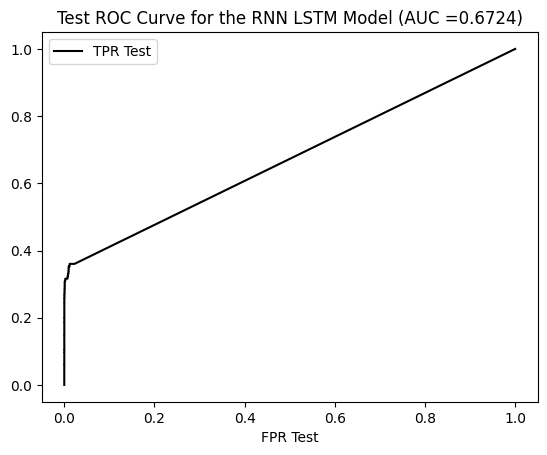

In [38]:
#Plot
roc_df_test_rnn.plot(x="FPR Test" ,
                     y="TPR Test",
                     color ="black",
                     style='-',
                     xlim=([-0.05,1.05]),
                     title =f"Test ROC Curve for the RNN LSTM Model (AUC ={auc_test_rnn})"
)
#